In [1]:
import scipy
%pip install mat73
%pip install neurokit2
import neurokit2 as nk
import mat73
import matplotlib.pyplot as plt
import numpy as np
%pip install scipy
from scipy.io import loadmat
import pandas as pd

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2" # suppress info and warning messages
%pip install tensorflow
import tensorflow.keras as keras
import math
import time
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.



In [2]:
file_path = 'C:/Users/emiik/Downloads/cuff+less+blood+pressure+estimation/Part_1.mat'
mat_data_part_1 = mat73.loadmat(file_path)
file_path = 'C:/Users/emiik/Downloads/cuff+less+blood+pressure+estimation/Part_2.mat'
mat_data_part_2 = mat73.loadmat(file_path)
file_path = 'C:/Users/emiik/Downloads/cuff+less+blood+pressure+estimation/Part_3.mat'
mat_data_part_3 = mat73.loadmat(file_path)
file_path = 'C:/Users/emiik/Downloads/cuff+less+blood+pressure+estimation/Part_4.mat'
mat_data_part_4 = mat73.loadmat(file_path)

In [3]:
mat_data_part_1 # viewing the dataset, find out why the dataset is divided up into 4 different parts

{'Part_1': [array([[ 1.75953079e+00,  1.71847507e+00,  1.68426197e+00, ...,
           1.64418377e+00,  1.60019550e+00,  1.56598240e+00],
         [ 6.70629552e+01,  6.93586281e+01,  7.53664529e+01, ...,
           7.64410232e+01,  8.18138747e+01,  9.13873191e+01],
         [-6.06060606e-02, -7.52688172e-02, -7.03812317e-02, ...,
          -1.00195503e-01, -9.04203324e-02, -4.54545455e-02]],
        shape=(3, 61000)),
  array([[ 2.40957967,  2.32942326,  2.23851417, ...,  1.24046921,
           1.23069404,  1.21994135],
         [73.75459745, 73.1684682 , 72.53349484, ..., 99.15353167,
          96.22288542, 93.19455095],
         [ 0.18475073,  0.17986315,  0.16959922, ...,  0.29472141,
           0.31964809,  0.33968719]], shape=(3, 61000)),
  array([[  1.21212121,   1.20136852,   1.19354839, ...,   1.34506354,
            1.33040078,   1.31671554],
         [ 94.80640639,  91.87576014,  88.55436105, ..., 127.38542394,
          124.16171306, 120.74262576],
         [  0.214565  ,   

In [4]:
print("Variables in file:", mat_data_part_1.keys())

Variables in file: dict_keys(['Part_1'])


In [5]:
print("Variable content:", mat_data_part_1['Part_1'])

Variable content: [array([[ 1.75953079e+00,  1.71847507e+00,  1.68426197e+00, ...,
         1.64418377e+00,  1.60019550e+00,  1.56598240e+00],
       [ 6.70629552e+01,  6.93586281e+01,  7.53664529e+01, ...,
         7.64410232e+01,  8.18138747e+01,  9.13873191e+01],
       [-6.06060606e-02, -7.52688172e-02, -7.03812317e-02, ...,
        -1.00195503e-01, -9.04203324e-02, -4.54545455e-02]],
      shape=(3, 61000)), array([[ 2.40957967,  2.32942326,  2.23851417, ...,  1.24046921,
         1.23069404,  1.21994135],
       [73.75459745, 73.1684682 , 72.53349484, ..., 99.15353167,
        96.22288542, 93.19455095],
       [ 0.18475073,  0.17986315,  0.16959922, ...,  0.29472141,
         0.31964809,  0.33968719]], shape=(3, 61000)), array([[  1.21212121,   1.20136852,   1.19354839, ...,   1.34506354,
          1.33040078,   1.31671554],
       [ 94.80640639,  91.87576014,  88.55436105, ..., 127.38542394,
        124.16171306, 120.74262576],
       [  0.214565  ,   0.22482893,   0.23460411, .

In [6]:
print(len(mat_data_part_1['Part_1']))

3000


In [7]:
for i in range(5):
    patient_data = np.array(mat_data_part_1['Part_1'][i])
    print(f"Shape of patient {i}'s data: {patient_data.shape}")

Shape of patient 0's data: (3, 61000)
Shape of patient 1's data: (3, 61000)
Shape of patient 2's data: (3, 50000)
Shape of patient 3's data: (3, 70000)
Shape of patient 4's data: (3, 69000)


In [8]:
# finding a way to find summary statistics of PPG data
PPG_signal = mat_data_part_1['Part_1'][0][0]
PPG_series = pd.Series(PPG_signal)
print(PPG_series.describe())

all_patient_stats = []
for patient_data in mat_data_part_1['Part_1']:
    ppg_signal = patient_data[0]
    ppg_series = pd.Series(ppg_signal).describe()
    all_patient_stats.append(ppg_series)

stats_df = pd.DataFrame(all_patient_stats)
display(stats_df)
print(f"Average mean across all patient PPG signals: {stats_df.mean()}")

count    61000.000000
mean         1.839741
std          0.631981
min          0.000000
25%          1.309873
50%          1.623656
75%          2.422287
max          4.001955
dtype: float64


,count,mean,std,min,25%,50%,75%,max
0,61000.0,1.839741,0.631981,0.000000,1.309873,1.623656,2.422287,4.001955
1,61000.0,1.833976,0.625294,0.000000,1.323558,1.616813,2.401760,4.001955
2,50000.0,1.828620,0.634882,0.000000,1.320381,1.634409,2.368524,4.001955
3,70000.0,1.826783,0.613026,0.000000,1.312805,1.617791,2.381232,3.997067
4,69000.0,1.772849,0.625158,0.348974,1.275660,1.540567,2.286413,4.001955
...,...,...,...,...,...,...,...,...
2995,9000.0,0.468863,0.141927,0.215054,0.357771,0.427175,0.593353,0.938416
2996,46000.0,0.473829,0.144109,0.179863,0.361681,0.437928,0.601173,0.951124
2997,9000.0,0.484749,0.138679,0.147605,0.382209,0.457478,0.605083,0.878788
2998,60000.0,0.485613,0.135654,0.022483,0.385142,0.462366,0.603128,0.999022


Average mean across all patient PPG signals: count    27591.333333
mean         1.533448
std          0.516668
min          0.463443
25%          1.119384
50%          1.388517
75%          1.923976
max          3.019851
dtype: float64


In [9]:
for patient_data in mat_data_part_1['Part_1']:
    ppg_signal = patient_data[0]
    signals, info = nk.ppg_process()

TypeError: ppg_process() missing 1 required positional argument: 'ppg_signal'

In [18]:
import numpy as np
import pandas as pd
import neurokit2 as nk
from scipy.signal import find_peaks

FS = 125  # sample rate

def extract_features(record, fs=FS):
    ppg, abp, ecg = record  

    ppg_signals, ppg_info = nk.ppg_process(ppg, sampling_rate=fs)
    ecg_signals, ecg_info = nk.ecg_process(ecg, sampling_rate=fs)
    ppg_peaks = np.asarray(ppg_info["PPG_Peaks"])
    r_peaks = np.asarray(ecg_info["ECG_R_Peaks"])

    feats = {
        "ppg_rate_mean": ppg_signals["PPG_Rate"].mean(),
        "ecg_rate_mean": ecg_signals["ECG_Rate"].mean(),
        "ppg_peak_amp_mean": ppg_signals["PPG_Clean"].values[ppg_peaks].mean(),
    }

    # HRV from PPG peaks
    feats.update(nk.hrv_time(ppg_peaks, sampling_rate=fs).iloc[0].to_dict())

    # Pulse transit time
    ptt = []
    for r in r_peaks:
        nxt = ppg_peaks[(ppg_peaks > r) & (ppg_peaks < r + int(0.6 * fs))]
        if len(nxt):
            ptt.append((nxt[0] - r) / fs)
    feats["ptt_mean"] = np.mean(ptt) if ptt else np.nan
    feats["ptt_std"] = np.std(ptt) if ptt else np.nan

    # Target features
    sys_idx, _ = find_peaks(abp, distance=int(0.4 * fs))
    dia_idx, _ = find_peaks(-abp, distance=int(0.4 * fs))
    feats["SBP"] = np.median(abp[sys_idx])
    feats["DBP"] = np.median(abp[dia_idx])
    return feats

records = mat_data_part_1["Part_1"]
rows = []
for i, rec in enumerate(records[:50]):  # test on a subset first; all 3000 takes a while
    try:
        f = extract_features(np.asarray(rec))
        f["record"] = i
        rows.append(f)
    except Exception as e:
        print(f"record {i} skipped: {e}")

features_df = pd.DataFrame(rows)
features_df.head()

,ppg_rate_mean,ecg_rate_mean,ppg_peak_amp_mean,HRV_MeanNN,HRV_SDNN,HRV_SDANN1,HRV_SDNNI1,HRV_SDANN2,HRV_SDNNI2,HRV_SDANN5,...,HRV_pNN20,HRV_MinNN,HRV_MaxNN,HRV_HTI,HRV_TINN,ptt_mean,ptt_std,SBP,DBP,record
0,122.557129,122.246968,1.075223,489.929648,38.807256,4.232898,29.273553,2.390503,31.385674,NaN,...,6.834171,320.0,1240.0,3.090062,0.0,0.078216,0.028747,133.051340,73.070780,0
1,118.785588,118.607080,1.065020,505.435685,34.421325,9.768528,27.914512,8.769788,29.668660,NaN,...,7.780083,328.0,1032.0,3.358885,0.0,0.063129,0.035557,129.729941,70.237822,1
2,114.142067,115.220069,1.067337,526.353562,57.621290,10.622847,48.916857,9.688795,51.736273,NaN,...,11.345646,352.0,1208.0,4.306818,0.0,0.057927,0.059351,136.568116,80.690460,2
3,118.134847,117.577966,1.077717,508.076294,23.225253,5.068535,18.474590,4.280664,18.879384,NaN,...,7.175295,320.0,1064.0,2.801527,0.0,0.060255,0.018242,129.632253,71.849677,3
4,109.090760,108.381740,1.119573,550.425574,39.107016,7.382595,28.535163,8.417399,28.726204,NaN,...,8.091908,336.0,1400.0,3.537102,0.0,0.055968,0.114128,134.174754,71.068172,4


In [20]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from scipy.signal import find_peaks
from sklearn.model_selection import GroupShuffleSplit

FS = 125
WIN = 8 * FS          # 8-second windows -> 1000 samples
STEP = WIN            # non-overlapping; set to WIN // 2 for 50% overlap (more data)
MAX_WIN_PER_REC = 20  # cap so long records don't dominate and memory stays reasonable

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: []


In [21]:
def zscore(x):
    s = x.std()
    return (x - x.mean()) / s if s > 1e-6 else None

def bp_targets(abp, fs=FS):
    sys_idx, _ = find_peaks(abp, distance=int(0.4 * fs))
    dia_idx, _ = find_peaks(-abp, distance=int(0.4 * fs))
    if len(sys_idx) < 3 or len(dia_idx) < 3:
        return None
    return np.median(abp[sys_idx]), np.median(abp[dia_idx])

def make_windows(records, rec_offset=0):
    X, y, groups = [], [], []
    for i, rec in enumerate(records):
        rec = np.asarray(rec, dtype=np.float32)
        if rec.ndim != 2 or rec.shape[0] != 3:
            continue
        ppg, abp, ecg = rec
        n = 0
        for start in range(0, len(ppg) - WIN + 1, STEP):
            if n >= MAX_WIN_PER_REC:
                break
            sl = slice(start, start + WIN)
            p, e = zscore(ppg[sl]), zscore(ecg[sl])
            t = bp_targets(abp[sl])
            if p is None or e is None or t is None:
                continue
            sbp, dbp = t
            # drop physiologically implausible / artefact windows
            if not (70 <= sbp <= 200 and 40 <= dbp <= 120 and sbp - dbp >= 10):
                continue
            X.append(np.stack([p, e], axis=-1))   # (WIN, 2)
            y.append([sbp, dbp])
            groups.append(rec_offset + i)
            n += 1
    return np.asarray(X, np.float32), np.asarray(y, np.float32), np.asarray(groups)

# Start with Part_1; add the other parts once everything works:
# all_records = [mat_data_part_1["Part_1"], mat_data_part_2["Part_2"],
#                mat_data_part_3["Part_3"], mat_data_part_4["Part_4"]]
all_records = [mat_data_part_1["Part_1"]]

Xs, ys, gs, offset = [], [], [], 0
for recs in all_records:
    Xp, yp, gp = make_windows(recs, rec_offset=offset)
    Xs.append(Xp); ys.append(yp); gs.append(gp)
    offset += len(recs)
X, y, groups = np.concatenate(Xs), np.concatenate(ys), np.concatenate(gs)
print("X:", X.shape, "y:", y.shape, "records used:", len(np.unique(groups)))

X: (39274, 1000, 2) y: (39274, 2) records used: 2987


In [22]:
# Record-wise split: 70% train, 15% val, 15% test
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss.split(X, y, groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_rel, test_rel = next(gss2.split(X[temp_idx], y[temp_idx], groups[temp_idx]))
val_idx, test_idx = temp_idx[val_rel], temp_idx[test_rel]

X_train, y_train = X[train_idx], y[train_idx]
X_val,   y_val   = X[val_idx],   y[val_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

# Standardise targets with training statistics only
y_mean, y_std = y_train.mean(axis=0), y_train.std(axis=0)
norm = lambda t: (t - y_mean) / y_std
denorm = lambda t: t * y_std + y_mean

print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)} windows")
print("SBP/DBP mean:", y_mean, " std:", y_std)

train 27499 | val 5956 | test 5819 windows
SBP/DBP mean: [131.71376  66.23721]  std: [23.720762 11.161703]


In [23]:
def res_block(x, filters, kernel_size=7, stride=1):
    shortcut = x
    y = layers.Conv1D(filters, kernel_size, strides=stride, padding="same", use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.ReLU()(y)
    y = layers.Conv1D(filters, kernel_size, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    # projection shortcut when shape changes
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv1D(filters, 1, strides=stride, use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    y = layers.Add()([y, shortcut])
    return layers.ReLU()(y)

def build_resnet1d(input_shape, n_outputs=2, stages=(32, 64, 128, 256), blocks_per_stage=2):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(stages[0], 15, strides=2, padding="same", use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling1D(3, strides=2, padding="same")(x)
    for i, f in enumerate(stages):
        for b in range(blocks_per_stage):
            x = res_block(x, f, stride=2 if (b == 0 and i > 0) else 1)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(n_outputs, name="sbp_dbp")(x)
    return models.Model(inp, out, name="ResNet1D_BP")

model = build_resnet1d(X_train.shape[1:])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss=tf.keras.losses.Huber(),
              metrics=["mae"])
model.summary()

Model: "ResNet1D_BP"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1000, 2)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 500, 32)   │        960 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 500, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 500, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 250, 32)   │          0 │ re_lu[0][0]       │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 250, 32)   │      7,168 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 32)   │        128 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 250, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 250, 32)   │      7,168 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 32)   │        128 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 250, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 250, 32)   │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 250, 32)   │      7,168 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 32)   │        128 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 250, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 250, 32)   │      7,168 │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 250, 32)   │        128 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 250, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 250, 32)   │          0 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 125, 64)   │     14,336 │ re_lu_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,206,210 (8.42 MB)

 Trainable params: 2,201,410 (8.40 MB)

 Non-trainable params: 4,800 (18.75 KB)

Epoch 1/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 137s 288ms/step - loss: 0.2865 - mae: 0.6115 - val_loss: 0.3674 - val_mae: 0.7321 - learning_rate: 0.0010
Epoch 2/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 107s 250ms/step - loss: 0.1853 - mae: 0.4672 - val_loss: 0.2759 - val_mae: 0.6069 - learning_rate: 0.0010
Epoch 3/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 109s 254ms/step - loss: 0.1463 - mae: 0.4075 - val_loss: 0.2535 - val_mae: 0.5748 - learning_rate: 0.0010
Epoch 4/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 110s 255ms/step - loss: 0.1225 - mae: 0.3683 - val_loss: 0.3050 - val_mae: 0.6464 - learning_rate: 0.0010
Epoch 5/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 109s 252ms/step - loss: 0.1050 - mae: 0.3395 - val_loss: 0.2425 - val_mae: 0.5512 - learning_rate: 0.0010
Epoch 6/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 107s 249ms/step - loss: 0.0919 - mae: 0.3161 - val_loss: 0.1976 - val_mae: 0.4887 - learning_rate: 0.0010
Epoch 7/100
430/430 ━━━━━━━━━━━━━━━━━━━━ 109s 254ms/step - loss: 0.0815 - mae: 0.2976 - val_loss: 0.2244 - val_mae: 0.

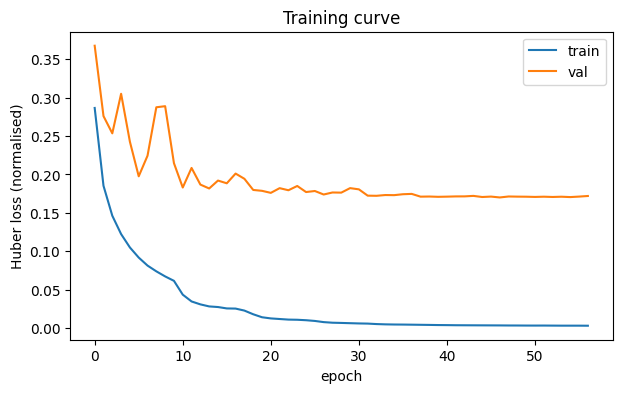

In [24]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    callbacks.ModelCheckpoint("resnet1d_bp.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(
    X_train, norm(y_train),
    validation_data=(X_val, norm(y_val)),
    epochs=100, batch_size=64, callbacks=cbs, verbose=1,
)

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("Huber loss (normalised)"); plt.legend(); plt.title("Training curve")
plt.show()

23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 181ms/step
SBP: MAE 9.41 | ME +0.44 ± SD 14.38 mmHg | AAMI FAIL
DBP: MAE 4.67 | ME -0.26 ± SD 7.16 mmHg | AAMI PASS
Mean-predictor baseline MAE -> SBP 21.31, DBP 8.90


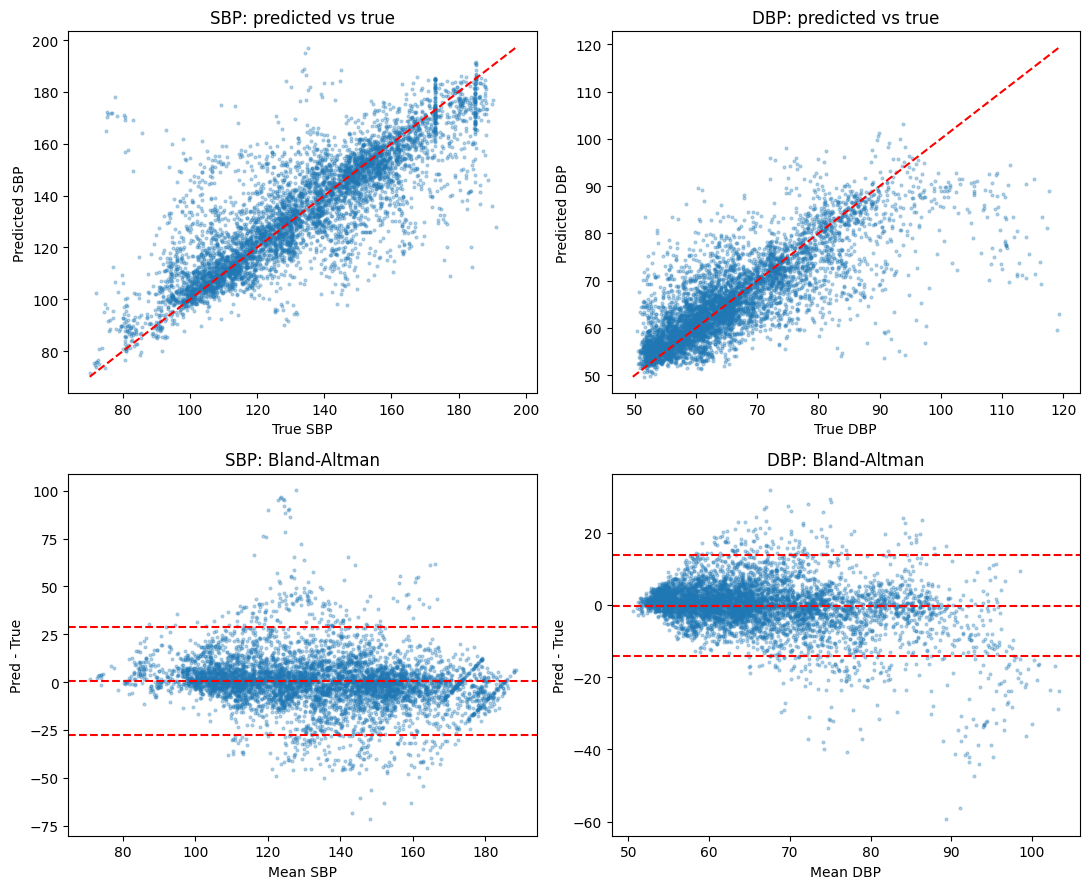

In [25]:
y_pred = denorm(model.predict(X_test, batch_size=256))

for k, name in enumerate(["SBP", "DBP"]):
    err = y_pred[:, k] - y_test[:, k]
    mae, me, sd = np.abs(err).mean(), err.mean(), err.std()
    aami = "PASS" if abs(me) <= 5 and sd <= 8 else "FAIL"
    print(f"{name}: MAE {mae:.2f} | ME {me:+.2f} ± SD {sd:.2f} mmHg | AAMI {aami}")

# Baseline: always predicting the training mean. The ResNet should beat this clearly.
base = np.abs(y_test - y_mean).mean(axis=0)
print(f"Mean-predictor baseline MAE -> SBP {base[0]:.2f}, DBP {base[1]:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for k, name in enumerate(["SBP", "DBP"]):
    t, p = y_test[:, k], y_pred[:, k]
    ax = axes[0, k]
    ax.scatter(t, p, s=4, alpha=0.3)
    lims = [min(t.min(), p.min()), max(t.max(), p.max())]
    ax.plot(lims, lims, "r--")
    ax.set(xlabel=f"True {name}", ylabel=f"Predicted {name}", title=f"{name}: predicted vs true")
    ax = axes[1, k]
    mean, diff = (t + p) / 2, p - t
    md_, sd_ = diff.mean(), diff.std()
    ax.scatter(mean, diff, s=4, alpha=0.3)
    for v in (md_, md_ + 1.96 * sd_, md_ - 1.96 * sd_):
        ax.axhline(v, color="r", ls="--")
    ax.set(xlabel=f"Mean {name}", ylabel="Pred - True", title=f"{name}: Bland-Altman")
plt.tight_layout(); plt.show()